# Modelado y evaluación

**Proyecto:** Predicción de la asistencia actual al nivel superior en jóvenes de 18 a 24 años con secundario completo (EPH – INDEC)

**Autora:** Liliana Elizabeth Iñigo

**Materia:** Aprendizaje Automático

**Docente:** Nicolás Caballero

Esta notebook entrena, compara y evalúa los modelos de clasificación. Usa las matrices preparadas en `3.0-lei-preprocesamiento.ipynb`.

1. Planteo: qué se predice, cuándo, para qué y qué clase interesa detectar
2. Datos de entrada y conjunto de prueba reservado
3. Esquema de validación y métricas
4. Modelo de referencia (línea base)
5. Ajuste de hiperparámetros por validación cruzada: regresión logística, KNN, SVM, árbol de decisión y Random Forest
6. Comparación de los modelos en validación
7. Análisis de sensibilidad: modelos sin la variable de "zona gris"
8. Elección del modelo final y del umbral de decisión
9. Evaluación final en el conjunto de prueba (una sola vez)
10. Interpretación del modelo
11. Cómo predicen los modelos (material para el video)
12. Conclusiones y limitaciones

> **Regla de trabajo:** todas las decisiones (hiperparámetros, modelo final, umbral, conservar o no una variable) se toman **solo con el conjunto de entrenamiento, mediante validación cruzada**. El conjunto de prueba (1T 2026) se usa **una única vez**, en la sección 9, después de cerrar todas las decisiones.

## 1. Planteo

| | |
|---|---|
| **Cada fila** | Un joven de 18 a 24 años con secundario completo y sin estudio superior terminado, con su situación y la de su hogar en el trimestre en que fue encuestado |
| **Qué se predice** | `asiste_superior`: 1 = asiste actualmente al nivel superior · 0 = no asiste |
| **Cuándo** | En el momento de la encuesta, con información que puede conocerse sin saber si el joven asiste (sus datos personales, los del hogar y los del jefe/a) |
| **Para qué** | Identificar jóvenes con perfil de **no asistencia**, para orientar becas, tutorías o acompañamientos hacia ellos |

**Clase de interés: "no asiste" (0).** Son los jóvenes a quienes se dirigiría la acción. Por eso las métricas principales se calculan para esa clase:

- **Recall de "no asiste":** de todos los jóvenes que no asisten, qué proporción identifica el modelo. Un recall bajo significa que muchos jóvenes que necesitarían el acompañamiento quedan sin detectar.
- **Precisión de "no asiste":** de los jóvenes que el modelo marca como "no asiste", qué proporción realmente no asiste. Una precisión baja significa que se dirigen recursos a jóvenes que ya asisten.
- **F1 de "no asiste":** combina las dos anteriores (media armónica). Es el **criterio de selección**: si solo se maximizara el recall, el mejor "modelo" sería marcar a todos como "no asiste", que tiene recall 1 pero no sirve para orientar nada.

También se informan la exactitud y la exactitud balanceada, pero no se usan para elegir: una exactitud alta puede esconder un modelo que no detecta la clase de interés (sección 4).

In [1]:
# Librerías: modelos vistos en la cursada, validación cruzada y métricas de scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import (make_scorer, f1_score, recall_score, precision_score, accuracy_score,
                             balanced_accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

pd.set_option("display.max_columns", 60)
SEMILLA = 42                                   # semilla fija para que los resultados se puedan reproducir

# Rutas relativas a la carpeta notebooks/ del repositorio. Si se ejecuta desde otra ubicación,
# reemplazar por la ruta local donde se encuentran las carpetas data/, reports/ y models/
PROCESSED = "../data/processed/"
FIGURAS = "../reports/figures/"
REPORTES = "../reports/"
MODELOS = "../models/"

## 2. Datos de entrada y conjunto de prueba reservado

Se usan las dos matrices de la notebook 3.0:

- **Escalada** (`matriz_preparada_escalada.csv`): para regresión logística, KNN y SVM. KNN y SVM se basan en distancias y la regresión logística regularizada penaliza los coeficientes: sin escalar, una variable con valores grandes (por ejemplo, el percentil, de 0 a 100) dominaría a otra con valores chicos (por ejemplo, la cantidad de menores).
- **Sin escalar** (`matriz_preparada_sin_escalar.csv`): para el árbol de decisión y Random Forest, que trabajan con umbrales sobre cada variable por separado y no dependen de la escala.

Las dos tienen las mismas filas y las mismas columnas; solo cambia la escala de las numéricas. La columna `codusu` (vivienda) no es una variable de entrada: se usa para agrupar en la validación.

In [2]:
# Lectura de las matrices y separación en entrenamiento y prueba según la columna particion
escalada = pd.read_csv(PROCESSED + "matriz_preparada_escalada.csv")
sin_escalar = pd.read_csv(PROCESSED + "matriz_preparada_sin_escalar.csv")
NO_ENTRADA = ["codusu", "particion", "asiste_superior"]

def separar(matriz, particion):
    filas = matriz[matriz["particion"] == particion]
    return filas.drop(columns=NO_ENTRADA), filas["asiste_superior"], filas["codusu"]

X_train_esc, y_train, grupos = separar(escalada, "entrenamiento")
X_train_sin, _, _ = separar(sin_escalar, "entrenamiento")
X_test_esc, y_test, _ = separar(escalada, "prueba")          # reservado: no se usa hasta la sección 9
X_test_sin, _, _ = separar(sin_escalar, "prueba")

# Controles: mismas filas y etiquetas en las dos matrices
assert (escalada["asiste_superior"] == sin_escalar["asiste_superior"]).all()
assert list(X_train_esc.columns) == list(X_train_sin.columns)
print(f"Entrenamiento: {X_train_esc.shape[0]:,} jóvenes · {X_train_esc.shape[1]} columnas de entrada")
print(f"Prueba (reservada): {X_test_esc.shape[0]:,} jóvenes")
print(f"Proporción de 'no asiste' en entrenamiento: {(y_train == 0).mean():.1%}")

Entrenamiento: 6,059 jóvenes · 55 columnas de entrada
Prueba (reservada): 3,497 jóvenes
Proporción de 'no asiste' en entrenamiento: 44.1%


## 3. Esquema de validación y métricas

**Validación cruzada de 5 pliegues, estratificada y agrupada por vivienda** (`StratifiedGroupKFold`):

- El entrenamiento se divide en 5 partes. Cada configuración se entrena 5 veces con 4 partes y se evalúa con la parte restante; se informa el promedio y el desvío de esas 5 evaluaciones.
- **Agrupada por vivienda (`codusu`):** dentro del entrenamiento hay hogares con más de un joven (por ejemplo, hermanos). Si un hermano quedara en la parte de entrenamiento y otro en la de validación, el modelo podría "reconocer" el hogar y la validación se vería mejor de lo que es. Agrupar mantiene a todos los jóvenes de una vivienda en el mismo pliegue, con el mismo criterio usado para separar entrenamiento y prueba.
- **Estratificada:** cada pliegue mantiene una proporción de clases parecida a la del total.

**Criterio de selección:** F1 de la clase "no asiste". En cada modelo se elige la configuración con mayor F1 promedio en validación (`refit="f1_no_asiste"`).

In [3]:
# Pliegues agrupados por vivienda y métricas calculadas para la clase de interés (0 = no asiste)
validacion = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
METRICAS = {
    "f1_no_asiste": make_scorer(f1_score, pos_label=0),
    "recall_no_asiste": make_scorer(recall_score, pos_label=0),
    "precision_no_asiste": make_scorer(precision_score, pos_label=0, zero_division=0),
    "exactitud": "accuracy",
    "exactitud_balanceada": "balanced_accuracy",
}

# Control: ninguna vivienda aparece en más de un pliegue y la proporción de clases es parecida en todos
for i, (_, idx_val) in enumerate(validacion.split(X_train_esc, y_train, grupos), start=1):
    print(f"Pliegue {i}: {len(idx_val):,} jóvenes · {(y_train.iloc[idx_val] == 0).mean():.1%} no asiste")
viviendas_por_pliegue = [set(grupos.iloc[idx]) for _, idx in validacion.split(X_train_esc, y_train, grupos)]
print("Viviendas repetidas entre pliegues:", sum(len(a & b) for i, a in enumerate(viviendas_por_pliegue)
                                                for b in viviendas_por_pliegue[i + 1:]))

Pliegue 1: 1,211 jóvenes · 44.1% no asiste
Pliegue 2: 1,211 jóvenes · 44.1% no asiste
Pliegue 3: 1,213 jóvenes · 44.2% no asiste
Pliegue 4: 1,212 jóvenes · 44.1% no asiste
Pliegue 5: 1,212 jóvenes · 44.1% no asiste
Viviendas repetidas entre pliegues: 0


In [4]:
# Función auxiliar: corre la búsqueda de hiperparámetros y devuelve la tabla de resultados ordenada
def buscar(modelo, grilla, X):
    busqueda = GridSearchCV(modelo, grilla, scoring=METRICAS, refit="f1_no_asiste", cv=validacion, n_jobs=-1)
    busqueda.fit(X, y_train, groups=grupos)
    resultados = pd.DataFrame(busqueda.cv_results_)
    columnas = ["params"] + [f"{t}_test_{m}" for m in METRICAS for t in ("mean", "std")]
    tabla = resultados[columnas].sort_values("mean_test_f1_no_asiste", ascending=False).reset_index(drop=True)
    return busqueda, tabla

def resumen_validacion(nombre, busqueda):
    # Fila con las métricas promedio (y desvío del F1) de la mejor configuración de cada modelo
    r = pd.DataFrame(busqueda.cv_results_).loc[busqueda.best_index_]
    fila = {"modelo": nombre, "hiperparámetros elegidos": str(busqueda.best_params_)}
    for m in METRICAS:
        fila[m] = r[f"mean_test_{m}"]
    fila["desvío f1"] = r["std_test_f1_no_asiste"]
    return fila

comparacion = []

## 4. Modelo de referencia (línea base)

Antes de comparar modelos conviene saber cuánto se obtiene **sin aprender nada**. El clasificador de referencia predice siempre la clase más frecuente del entrenamiento ("asiste").

In [5]:
# Línea base: predecir siempre la clase mayoritaria
base, tabla_base = buscar(DummyClassifier(strategy="most_frequent"), {}, X_train_esc)
comparacion.append(resumen_validacion("Referencia (clase mayoritaria)", base))
pd.DataFrame(comparacion).round(3)

,modelo,hiperparámetros elegidos,f1_no_asiste,recall_no_asiste,precision_no_asiste,exactitud,exactitud_balanceada,desvío f1
0,Referencia (clase mayoritaria),{},0.0,0.0,0.0,0.559,0.5,0.0


**Lectura:** la línea base tiene una exactitud cercana al 56 % (la proporción de jóvenes que asisten), pero **recall 0 en "no asiste"**: no detecta a ningún joven de la clase de interés. Es el mismo caso del ejemplo visto en clase: una exactitud aceptable no garantiza que el modelo sirva. Cualquier modelo útil tiene que superar claramente este punto de partida en las métricas de "no asiste".

## 5. Ajuste de hiperparámetros por validación cruzada

Para cada modelo se prueba una grilla de valores y se elige el de mayor F1 de "no asiste" en validación. Las tablas completas quedan en la notebook como evidencia de la elección.

### 5.1 Regresión logística

Estima la **probabilidad** de que un joven asista combinando las variables de entrada con pesos (coeficientes), y clasifica comparando esa probabilidad con un umbral (por defecto 0,5). El hiperparámetro `C` controla la regularización: valores chicos penalizan más los coeficientes grandes (modelo más simple) y valores grandes los dejan más libres.

In [6]:
# Regresión logística (matriz escalada): grilla de C, de mucha a poca regularización
logistica, tabla_logistica = buscar(LogisticRegression(max_iter=3000),
                                    {"C": [0.001, 0.01, 0.1, 1, 10, 100]}, X_train_esc)
comparacion.append(resumen_validacion("Regresión logística", logistica))
tabla_logistica.round(3)

,params,mean_test_f1_no_asiste,std_test_f1_no_asiste,mean_test_recall_no_asiste,std_test_recall_no_asiste,mean_test_precision_no_asiste,std_test_precision_no_asiste,mean_test_exactitud,std_test_exactitud,mean_test_exactitud_balanceada,std_test_exactitud_balanceada
0,{'C': 10},0.733,0.012,0.718,0.018,0.748,0.009,0.769,0.009,0.763,0.009
1,{'C': 100},0.732,0.011,0.717,0.018,0.748,0.008,0.768,0.008,0.763,0.009
2,{'C': 1},0.732,0.013,0.717,0.020,0.748,0.009,0.768,0.009,0.763,0.010
3,{'C': 0.1},0.730,0.013,0.714,0.022,0.748,0.008,0.767,0.009,0.762,0.010
4,{'C': 0.01},0.730,0.010,0.709,0.017,0.753,0.004,0.769,0.006,0.762,0.007
5,{'C': 0.001},0.660,0.008,0.579,0.012,0.769,0.007,0.737,0.004,0.721,0.005


**Lectura:** con regularización muy fuerte (`C = 0,001`) el modelo queda demasiado simple y el F1 cae. A partir de `C = 0,01` el F1 se estabiliza alrededor de 0,73 y las diferencias entre valores son menores que el desvío entre pliegues. Se elige el valor con mayor F1 promedio.

### 5.2 K vecinos más cercanos (KNN)

Clasifica a un joven según la clase de los **K jóvenes más parecidos** del entrenamiento (los más cercanos en distancia). Por eso necesita la matriz escalada. Con K chico el modelo sigue mucho los casos particulares (sobreajuste); con K grande se suaviza y tiende a la clase mayoritaria. También se prueba ponderar a los vecinos por cercanía (`weights="distance"`).

In [7]:
# KNN (matriz escalada): grilla de K y forma de ponderar a los vecinos
knn, tabla_knn = buscar(KNeighborsClassifier(),
                        {"n_neighbors": [5, 11, 21, 31, 51, 75, 101], "weights": ["uniform", "distance"]}, X_train_esc)
comparacion.append(resumen_validacion("KNN", knn))
tabla_knn.head(8).round(3)

,params,mean_test_f1_no_asiste,std_test_f1_no_asiste,mean_test_recall_no_asiste,std_test_recall_no_asiste,mean_test_precision_no_asiste,std_test_precision_no_asiste,mean_test_exactitud,std_test_exactitud,mean_test_exactitud_balanceada,std_test_exactitud_balanceada
0,"{'n_neighbors': 21, 'weights': 'distance'}",0.699,0.008,0.648,0.011,0.758,0.014,0.753,0.007,0.742,0.007
1,"{'n_neighbors': 31, 'weights': 'distance'}",0.695,0.006,0.635,0.010,0.768,0.011,0.754,0.005,0.742,0.005
2,"{'n_neighbors': 21, 'weights': 'uniform'}",0.694,0.007,0.640,0.010,0.757,0.010,0.750,0.006,0.739,0.005
3,"{'n_neighbors': 51, 'weights': 'distance'}",0.692,0.007,0.623,0.011,0.779,0.011,0.755,0.005,0.742,0.006
4,"{'n_neighbors': 31, 'weights': 'uniform'}",0.692,0.006,0.630,0.009,0.768,0.012,0.752,0.006,0.740,0.005
5,"{'n_neighbors': 11, 'weights': 'distance'}",0.692,0.007,0.644,0.015,0.747,0.013,0.746,0.005,0.736,0.005
6,"{'n_neighbors': 11, 'weights': 'uniform'}",0.690,0.004,0.641,0.012,0.748,0.014,0.746,0.005,0.735,0.004
7,"{'n_neighbors': 51, 'weights': 'uniform'}",0.686,0.004,0.614,0.007,0.778,0.010,0.752,0.004,0.738,0.004


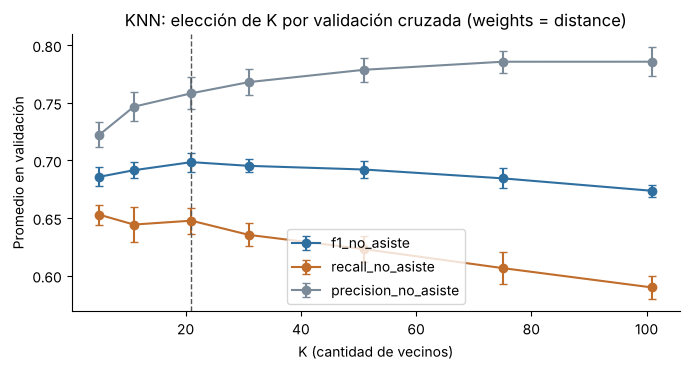

In [8]:
# Cómo cambia el desempeño en validación según K (con la ponderación elegida)
resultados_knn = pd.DataFrame(knn.cv_results_)
resultados_knn = resultados_knn[resultados_knn["param_weights"] == knn.best_params_["weights"]]
fig, eje = plt.subplots(figsize=(7, 3.8))
for metrica, color in [("f1_no_asiste", "#2f6f9f"), ("recall_no_asiste", "#c06c2b"), ("precision_no_asiste", "#7a8a99")]:
    eje.errorbar(resultados_knn["param_n_neighbors"].astype(int), resultados_knn[f"mean_test_{metrica}"],
                 yerr=resultados_knn[f"std_test_{metrica}"], marker="o", capsize=3, color=color, label=metrica)
eje.axvline(knn.best_params_["n_neighbors"], color="#555555", linestyle="--", linewidth=1)
eje.set_xlabel("K (cantidad de vecinos)")
eje.set_ylabel("Promedio en validación")
eje.set_title(f"KNN: elección de K por validación cruzada (weights = {knn.best_params_['weights']})")
eje.legend()
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURAS + "modelo_knn_eleccion_k.png", dpi=110)

**Lectura:** con K chico el F1 es más bajo; mejora al aumentar K hasta un máximo y después se estabiliza o baja levemente, porque con muchos vecinos el modelo se acerca a predecir la clase mayoritaria. El valor de K **sale de esta comparación en validación**, no del conjunto de prueba. La línea punteada marca el K elegido.

### 5.3 Máquina de vectores de soporte (SVM)

Busca la frontera de decisión que deja el **mayor margen entre la frontera y los ejemplos de entrenamiento más cercanos a ella** (los vectores de soporte), admitiendo algunos casos dentro del margen o mal clasificados con una penalización. `C` regula esa penalización: valores grandes penalizan más los errores y ajustan más al entrenamiento (margen más angosto); valores chicos toleran más errores (margen más ancho). Con el núcleo RBF la frontera puede ser curva, y `gamma` controla cuán local es la influencia de cada caso. Usa la matriz escalada porque el núcleo RBF se basa en distancias.

In [9]:
# SVM con núcleo RBF (matriz escalada): grilla de C y gamma
svm, tabla_svm = buscar(SVC(kernel="rbf", random_state=SEMILLA),
                        {"C": [0.1, 1, 10], "gamma": ["scale", 0.01]}, X_train_esc)
comparacion.append(resumen_validacion("SVM (RBF)", svm))
tabla_svm.round(3)

,params,mean_test_f1_no_asiste,std_test_f1_no_asiste,mean_test_recall_no_asiste,std_test_recall_no_asiste,mean_test_precision_no_asiste,std_test_precision_no_asiste,mean_test_exactitud,std_test_exactitud,mean_test_exactitud_balanceada,std_test_exactitud_balanceada
0,"{'C': 1, 'gamma': 'scale'}",0.737,0.015,0.726,0.023,0.749,0.008,0.772,0.010,0.767,0.012
1,"{'C': 10, 'gamma': 0.01}",0.734,0.009,0.726,0.020,0.743,0.009,0.768,0.005,0.764,0.006
2,"{'C': 0.1, 'gamma': 'scale'}",0.734,0.011,0.758,0.023,0.713,0.016,0.758,0.010,0.758,0.010
3,"{'C': 1, 'gamma': 0.01}",0.730,0.010,0.745,0.016,0.717,0.020,0.757,0.012,0.756,0.011
4,"{'C': 0.1, 'gamma': 0.01}",0.728,0.010,0.735,0.016,0.722,0.018,0.758,0.011,0.755,0.010
5,"{'C': 10, 'gamma': 'scale'}",0.716,0.011,0.701,0.015,0.731,0.012,0.754,0.009,0.749,0.009


### 5.4 Árbol de decisión

Divide a los jóvenes con preguntas sucesivas sobre una variable a la vez (por ejemplo, "¿es inactivo?") hasta llegar a grupos donde predomina una clase. `max_depth` limita la cantidad de preguntas encadenadas y `min_samples_leaf` exige un mínimo de jóvenes en cada grupo final: los dos evitan que el árbol memorice casos particulares. Usa la matriz sin escalar.

In [10]:
# Árbol de decisión (matriz sin escalar): grilla de profundidad y tamaño mínimo de las hojas
arbol, tabla_arbol = buscar(DecisionTreeClassifier(random_state=SEMILLA),
                            {"max_depth": [2, 3, 4, 5, 6, 8, 10, None], "min_samples_leaf": [1, 10, 30, 60, 100, 200]},
                            X_train_sin)
comparacion.append(resumen_validacion("Árbol de decisión", arbol))
tabla_arbol.head(8).round(3)

,params,mean_test_f1_no_asiste,std_test_f1_no_asiste,mean_test_recall_no_asiste,std_test_recall_no_asiste,mean_test_precision_no_asiste,std_test_precision_no_asiste,mean_test_exactitud,std_test_exactitud,mean_test_exactitud_balanceada,std_test_exactitud_balanceada
0,"{'max_depth': 3, 'min_samples_leaf': 100}",0.728,0.005,0.792,0.017,0.675,0.015,0.739,0.008,0.745,0.006
1,"{'max_depth': 3, 'min_samples_leaf': 60}",0.728,0.005,0.792,0.017,0.675,0.015,0.739,0.008,0.745,0.006
2,"{'max_depth': 3, 'min_samples_leaf': 1}",0.726,0.004,0.782,0.018,0.679,0.017,0.740,0.009,0.744,0.006
3,"{'max_depth': 3, 'min_samples_leaf': 10}",0.726,0.004,0.782,0.018,0.679,0.017,0.740,0.009,0.744,0.006
4,"{'max_depth': 3, 'min_samples_leaf': 30}",0.726,0.004,0.782,0.018,0.679,0.017,0.740,0.009,0.744,0.006
5,"{'max_depth': 4, 'min_samples_leaf': 200}",0.724,0.008,0.742,0.024,0.708,0.017,0.750,0.008,0.750,0.007
6,"{'max_depth': 5, 'min_samples_leaf': 200}",0.723,0.008,0.731,0.016,0.716,0.017,0.753,0.009,0.751,0.008
7,"{'max_depth': 6, 'min_samples_leaf': 200}",0.723,0.008,0.731,0.016,0.716,0.017,0.753,0.009,0.751,0.008


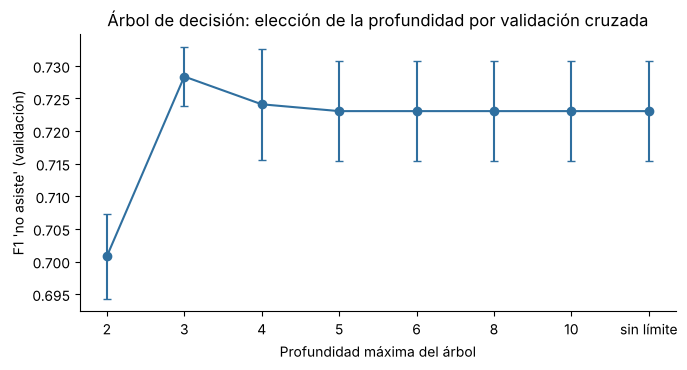

,param_min_samples_leaf,mean_test_f1_no_asiste,mean_test_recall_no_asiste
profundidad,,,
2,1,0.701,0.726
3,60,0.728,0.792
4,200,0.724,0.742
5,200,0.723,0.731
6,200,0.723,0.731
8,200,0.723,0.731
10,200,0.723,0.731
sin límite,200,0.723,0.731


In [11]:
# F1 de "no asiste" en validación según la profundidad (mejor min_samples_leaf para cada profundidad)
resultados_arbol = pd.DataFrame(arbol.cv_results_)
resultados_arbol["profundidad"] = resultados_arbol["param_max_depth"].astype(object).fillna("sin límite").astype(str)
mejor_por_profundidad = resultados_arbol.loc[resultados_arbol.groupby("profundidad")["mean_test_f1_no_asiste"].idxmax()]
orden = ["2", "3", "4", "5", "6", "8", "10", "sin límite"]
mejor_por_profundidad = mejor_por_profundidad.set_index("profundidad").loc[orden]
fig, eje = plt.subplots(figsize=(7, 3.8))
eje.errorbar(orden, mejor_por_profundidad["mean_test_f1_no_asiste"], yerr=mejor_por_profundidad["std_test_f1_no_asiste"],
             marker="o", capsize=3, color="#2f6f9f")
eje.set_xlabel("Profundidad máxima del árbol")
eje.set_ylabel("F1 'no asiste' (validación)")
eje.set_title("Árbol de decisión: elección de la profundidad por validación cruzada")
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURAS + "modelo_arbol_eleccion_profundidad.png", dpi=110)
mejor_por_profundidad[["param_min_samples_leaf", "mean_test_f1_no_asiste", "mean_test_recall_no_asiste"]].round(3)

**Lectura:** el mejor árbol en validación es **poco profundo**. Árboles más profundos no mejoran el F1 de "no asiste": empiezan a ajustarse a casos particulares del entrenamiento. Un árbol chico tiene además la ventaja de que se puede leer completo (sección 11).

### 5.5 Random Forest

Combina muchos árboles, cada uno entrenado con una muestra distinta de jóvenes y de variables, y decide por mayoría. Suele ser más estable que un árbol solo, a costa de ser menos interpretable. Se fija la cantidad de árboles (300) y se ajustan la profundidad y el tamaño mínimo de las hojas.

In [12]:
# Random Forest (matriz sin escalar): grilla de profundidad y tamaño mínimo de las hojas
bosque, tabla_bosque = buscar(RandomForestClassifier(n_estimators=300, random_state=SEMILLA),
                              {"max_depth": [6, 10, None], "min_samples_leaf": [1, 5, 20]}, X_train_sin)
comparacion.append(resumen_validacion("Random Forest", bosque))
tabla_bosque.round(3)

,params,mean_test_f1_no_asiste,std_test_f1_no_asiste,mean_test_recall_no_asiste,std_test_recall_no_asiste,mean_test_precision_no_asiste,std_test_precision_no_asiste,mean_test_exactitud,std_test_exactitud,mean_test_exactitud_balanceada,std_test_exactitud_balanceada
0,"{'max_depth': None, 'min_samples_leaf': 5}",0.737,0.005,0.717,0.013,0.758,0.005,0.774,0.002,0.768,0.003
1,"{'max_depth': None, 'min_samples_leaf': 1}",0.734,0.006,0.725,0.011,0.743,0.008,0.768,0.005,0.764,0.005
2,"{'max_depth': 10, 'min_samples_leaf': 1}",0.732,0.007,0.711,0.012,0.755,0.004,0.771,0.004,0.764,0.005
3,"{'max_depth': 10, 'min_samples_leaf': 20}",0.732,0.006,0.715,0.014,0.749,0.008,0.769,0.004,0.763,0.005
4,"{'max_depth': 10, 'min_samples_leaf': 5}",0.731,0.006,0.711,0.013,0.753,0.006,0.770,0.004,0.763,0.005
5,"{'max_depth': None, 'min_samples_leaf': 20}",0.728,0.006,0.708,0.013,0.749,0.009,0.766,0.004,0.760,0.004
6,"{'max_depth': 6, 'min_samples_leaf': 5}",0.725,0.005,0.700,0.013,0.753,0.008,0.766,0.003,0.759,0.004
7,"{'max_depth': 6, 'min_samples_leaf': 1}",0.723,0.004,0.699,0.015,0.749,0.013,0.763,0.004,0.757,0.003
8,"{'max_depth': 6, 'min_samples_leaf': 20}",0.722,0.008,0.698,0.012,0.748,0.014,0.763,0.008,0.756,0.007


## 6. Comparación de los modelos en validación

Todos los modelos se comparan con **los mismos pliegues, las mismas etiquetas y las mismas métricas**. Cada uno usa la preparación que le corresponde (escalada o sin escalar). Son métricas de **validación**: sirven para elegir, no son la evaluación final.

In [13]:
# Tabla comparativa: mejor configuración de cada modelo (promedio de los 5 pliegues)
tabla_comparacion = pd.DataFrame(comparacion).set_index("modelo")
tabla_comparacion.to_csv(REPORTES + "metricas_validacion.csv")
tabla_comparacion.round(3)

,hiperparámetros elegidos,f1_no_asiste,recall_no_asiste,precision_no_asiste,exactitud,exactitud_balanceada,desvío f1
modelo,,,,,,,
Referencia (clase mayoritaria),{},0.000,0.000,0.000,0.559,0.500,0.000
Regresión logística,{'C': 10},0.733,0.718,0.748,0.769,0.763,0.012
KNN,"{'n_neighbors': 21, 'weights': 'distance'}",0.699,0.648,0.758,0.753,0.742,0.008
SVM (RBF),"{'C': 1, 'gamma': 'scale'}",0.737,0.726,0.749,0.772,0.767,0.015
Árbol de decisión,"{'max_depth': 3, 'min_samples_leaf': 60}",0.728,0.792,0.675,0.739,0.745,0.005
Random Forest,"{'max_depth': None, 'min_samples_leaf': 5}",0.737,0.717,0.758,0.774,0.768,0.005


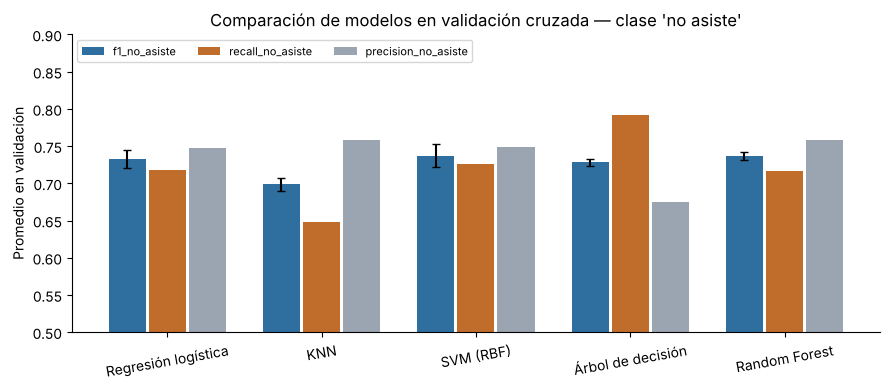

In [14]:
# Gráfico: F1, recall y precisión de "no asiste" en validación, con el desvío entre pliegues del F1
modelos = tabla_comparacion.drop(index="Referencia (clase mayoritaria)")
posiciones = np.arange(len(modelos))
fig, eje = plt.subplots(figsize=(9, 4))
for i, (metrica, color) in enumerate([("f1_no_asiste", "#2f6f9f"), ("recall_no_asiste", "#c06c2b"),
                                      ("precision_no_asiste", "#9aa5b1")]):
    eje.bar(posiciones + (i - 1) * 0.26, modelos[metrica], width=0.24, color=color, label=metrica,
            yerr=modelos["desvío f1"] if metrica == "f1_no_asiste" else None, capsize=3)
eje.set_xticks(posiciones)
eje.set_xticklabels(modelos.index, rotation=10)
eje.set_ylim(0.5, 0.9)
eje.set_ylabel("Promedio en validación")
eje.set_title("Comparación de modelos en validación cruzada — clase 'no asiste'")
eje.legend(loc="upper left", ncol=3, fontsize=8)
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURAS + "modelo_comparacion_validacion.png", dpi=110)

**Lectura:**

- Todos los modelos superan ampliamente a la línea base: pasan de no detectar a ningún joven que no asiste a detectar alrededor de 7 de cada 10, con una exactitud cercana al 77 %.
- Regresión logística, SVM y Random Forest quedan **prácticamente empatados** en F1 (alrededor de 0,73–0,74): las diferencias entre ellos son menores que el desvío entre pliegues, es decir, no son diferencias confiables.
- KNN queda algo por debajo, sobre todo en recall.
- El árbol poco profundo tiene el **recall más alto** pero la precisión más baja: marca como "no asiste" a más jóvenes, acertando menos en cada uno.

## 7. Análisis de sensibilidad: modelos sin `condicion_actividad`

La condición de actividad (ocupado, desocupado, inactivo) quedó señalada como **"zona gris"**: está disponible en el momento de la encuesta y no es un indicador educativo, pero se mide al mismo tiempo que la asistencia y en parte puede ser consecuencia de estudiar (quien estudia muchas veces no busca trabajo).

Para saber cuánto depende el desempeño de esa variable, se repite la validación de los mejores modelos **sin sus columnas**. Esta comparación se define antes de mirar la prueba.

In [15]:
# Validación de las mejores configuraciones con y sin las columnas de condicion_actividad
sin_actividad = [c for c in X_train_esc.columns if not c.startswith("condicion_actividad")]
print("Columnas quitadas:", [c for c in X_train_esc.columns if c.startswith("condicion_actividad")])

filas = []
for nombre, busqueda, X in [("Regresión logística", logistica, X_train_esc), ("SVM (RBF)", svm, X_train_esc),
                            ("Random Forest", bosque, X_train_sin)]:
    for version, columnas in [("con condicion_actividad", list(X.columns)), ("sin condicion_actividad", sin_actividad)]:
        r = cross_validate(busqueda.best_estimator_, X[columnas], y_train, groups=grupos, cv=validacion,
                           scoring=METRICAS, n_jobs=-1)
        filas.append({"modelo": nombre, "versión": version, **{m: r[f"test_{m}"].mean() for m in METRICAS}})
sensibilidad = pd.DataFrame(filas).set_index(["modelo", "versión"])
sensibilidad.round(3)

Columnas quitadas: ['condicion_actividad_desocupado', 'condicion_actividad_inactivo', 'condicion_actividad_ocupado']


f1_no_asiste  recall_no_asiste  \
modelo              versión                                                   
Regresión logística con condicion_actividad         0.733             0.718   
                    sin condicion_actividad         0.660             0.631   
SVM (RBF)           con condicion_actividad         0.737             0.726   
                    sin condicion_actividad         0.664             0.639   
Random Forest       con condicion_actividad         0.737             0.717   
                    sin condicion_actividad         0.664             0.648   

                                             precision_no_asiste  exactitud  \
modelo              versión                                                   
Regresión logística con condicion_actividad                0.748      0.769   
                    sin condicion_actividad                0.692      0.713   
SVM (RBF)           con condicion_actividad                0.749      0.772   
                    sin condicion_actividad                0.693      0.715   
Random Forest       con condicion_actividad                0.758      0.774   
                    sin condicion_actividad                0.683      0.711   

                                             exactitud_balanceada  
modelo              versión                                        
Regresión logística con condicion_actividad                 0.763  
                    sin condicion_actividad                 0.705  
SVM (RBF)           con condicion_actividad                 0.767  
                    sin condicion_actividad                 0.707  
Random Forest       con condicion_actividad                 0.768  
                    sin condicion_actividad                 0.705

**Lectura:** sin la condición de actividad, el F1 de "no asiste" baja de alrededor de 0,73 a 0,66 en todos los modelos, y el recall cae más (de alrededor de 0,72 a 0,63). Es la variable con más peso para distinguir las clases.

**Decisión:** se **conserva** en el modelo principal, porque está disponible en el escenario de uso (se conoce en el momento de la encuesta sin saber si el joven asiste) y no es una medida de la respuesta por definición. Pero como puede ser en parte consecuencia de estudiar, el modelo **sin** esta variable se informa también en la prueba (sección 9), como resultado complementario fijado de antemano. La diferencia muestra que el modelo se apoya mucho en esta variable. Una interpretación posible, que no puede comprobarse con estos datos (hipótesis), es que parte de lo que aprende es la relación entre estudiar y no trabajar; por eso se tiene en cuenta al interpretar los resultados.

## 8. Elección del modelo final y del umbral de decisión

### 8.1 Modelo final: regresión logística

La regresión logística **no es el modelo con el mayor F1 promedio**: SVM y Random Forest obtienen 0,737 frente a 0,733. Pero esa diferencia (0,004) es mucho menor que el desvío entre pliegues (alrededor de 0,01), así que en validación los tres resultan equivalentes. Entre ellos se elige el **más simple e interpretable**:

- sus coeficientes muestran en qué dirección se asocia cada variable con la asistencia;
- da una **probabilidad**, lo que permite elegir el umbral según el uso (por ejemplo, priorizar detectar más jóvenes que no asisten);
- es más rápido y fácil de explicar que un SVM o un bosque de 300 árboles.

### 8.2 Umbral de decisión

Por defecto, la regresión logística clasifica como "asiste" cuando la probabilidad estimada de asistir es al menos 0,50. Ese corte no tiene por qué ser el mejor para el objetivo. El umbral se elige **también por validación cruzada**: se obtienen probabilidades "fuera del pliegue" para cada joven del entrenamiento (cada probabilidad la calcula un modelo que no vio a ese joven) y se calcula el F1 de "no asiste" para varios umbrales.

In [16]:
# Probabilidades de asistir fuera del pliegue para el entrenamiento (cada joven es evaluado por un modelo que no lo vio)
modelo_final = logistica.best_estimator_
prob_validacion = cross_val_predict(modelo_final, X_train_esc, y_train, groups=grupos, cv=validacion,
                                    method="predict_proba")[:, 1]

filas = []
for umbral in np.round(np.arange(0.30, 0.71, 0.05), 2):
    prediccion = (prob_validacion >= umbral).astype(int)          # asiste si la probabilidad alcanza el umbral
    filas.append({"umbral": umbral,
                  "f1_no_asiste": f1_score(y_train, prediccion, pos_label=0),
                  "recall_no_asiste": recall_score(y_train, prediccion, pos_label=0),
                  "precision_no_asiste": precision_score(y_train, prediccion, pos_label=0),
                  "exactitud": accuracy_score(y_train, prediccion)})
tabla_umbrales = pd.DataFrame(filas).set_index("umbral")
UMBRAL = tabla_umbrales["f1_no_asiste"].idxmax()
print(f"Umbral elegido por validación: {UMBRAL:.2f}")
tabla_umbrales.round(3)

Umbral elegido por validación: 0.55


,f1_no_asiste,recall_no_asiste,precision_no_asiste,exactitud
umbral,,,,
0.30,0.632,0.509,0.834,0.739
0.35,0.674,0.576,0.811,0.754
0.40,0.701,0.631,0.790,0.763
0.45,0.720,0.674,0.772,0.768
0.50,0.733,0.718,0.748,0.769
0.55,0.746,0.765,0.728,0.770
0.60,0.746,0.800,0.698,0.759
0.65,0.745,0.835,0.672,0.747
0.70,0.741,0.863,0.649,0.734


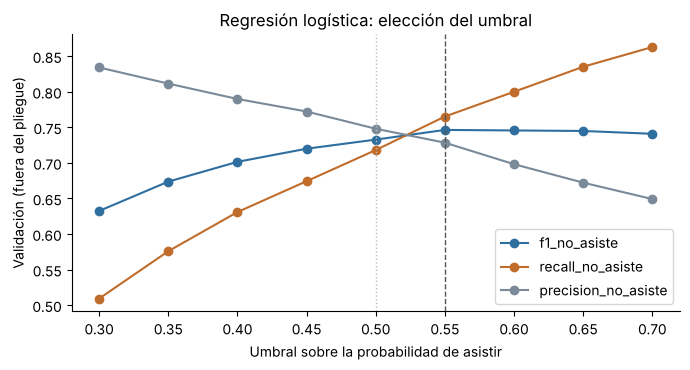

In [17]:
# Gráfico del efecto del umbral sobre recall y precisión de "no asiste"
fig, eje = plt.subplots(figsize=(7, 3.8))
for metrica, color in [("f1_no_asiste", "#2f6f9f"), ("recall_no_asiste", "#c06c2b"), ("precision_no_asiste", "#7a8a99")]:
    eje.plot(tabla_umbrales.index, tabla_umbrales[metrica], marker="o", color=color, label=metrica)
eje.axvline(0.5, color="#bbbbbb", linestyle=":", linewidth=1)
eje.axvline(UMBRAL, color="#555555", linestyle="--", linewidth=1)
eje.set_xlabel("Umbral sobre la probabilidad de asistir")
eje.set_ylabel("Validación (fuera del pliegue)")
eje.set_title("Regresión logística: elección del umbral")
eje.legend()
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURAS + "modelo_logistica_eleccion_umbral.png", dpi=110)

**Lectura:** al subir el umbral, el modelo exige una probabilidad de asistir más alta para clasificar como "asiste", así que marca a más jóvenes como "no asiste": **el recall de "no asiste" sube y la precisión baja**. El F1 es máximo en un umbral algo mayor que 0,50 (línea punteada), con una exactitud parecida. Se adopta ese umbral: detecta más jóvenes que no asisten a cambio de algunos falsos positivos más, lo que es razonable en el uso previsto (es preferible ofrecer un acompañamiento a alguien que ya estudia que dejar sin ofrecerlo a quien no estudia). La elección se hizo sin usar la prueba.

## 9. Evaluación final en el conjunto de prueba

Con todas las decisiones cerradas (modelo, hiperparámetros, umbral y variables), se entrena el modelo final con **todo el entrenamiento** y se evalúa **una sola vez** sobre la prueba: 3.497 jóvenes del 1.er trimestre de 2026, que no intervinieron en ninguna decisión ni en la preparación de los datos.

In [18]:
# Entrenamiento final con todo el conjunto de entrenamiento y predicción sobre la prueba con el umbral elegido
modelo_final.fit(X_train_esc, y_train)
prob_prueba = modelo_final.predict_proba(X_test_esc)[:, 1]
pred_prueba = (prob_prueba >= UMBRAL).astype(int)

print(f"Modelo final: regresión logística {logistica.best_params_} · umbral {UMBRAL:.2f}\n")
print(classification_report(y_test, pred_prueba, target_names=["No asiste (0)", "Asiste (1)"], digits=3))

Modelo final: regresión logística {'C': 10} · umbral 0.55

               precision    recall  f1-score   support

No asiste (0)      0.730     0.765     0.747      1625
   Asiste (1)      0.787     0.754     0.770      1872

     accuracy                          0.759      3497
    macro avg      0.758     0.760     0.759      3497
 weighted avg      0.760     0.759     0.759      3497



No asisten y el modelo los detecta: 1,243 · No asisten y el modelo dice que asisten: 382
Asisten y el modelo dice que no asisten: 460 · Asisten y el modelo acierta: 1,412


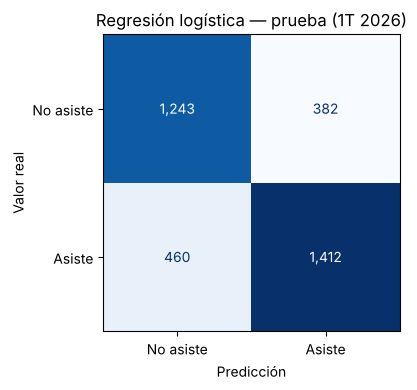

In [19]:
# Matriz de confusión en la prueba
fig, eje = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_prueba), display_labels=["No asiste", "Asiste"]).plot(
    ax=eje, cmap="Blues", colorbar=False, values_format=",")
eje.set_xlabel("Predicción")
eje.set_ylabel("Valor real")
eje.set_title("Regresión logística — prueba (1T 2026)")
plt.tight_layout()
plt.savefig(FIGURAS + "modelo_matriz_confusion_prueba.png", dpi=110)
vn, fp_asiste, fn_asiste, vp = confusion_matrix(y_test, pred_prueba).ravel()
print(f"No asisten y el modelo los detecta: {vn:,} · No asisten y el modelo dice que asisten: {fp_asiste:,}")
print(f"Asisten y el modelo dice que no asisten: {fn_asiste:,} · Asisten y el modelo acierta: {vp:,}")

**Resultados complementarios en la prueba.** Para dar contexto se informan en la misma tabla, con las mismas observaciones, etiquetas y métricas: la línea base, los demás modelos con su configuración ya elegida por validación (umbral habitual) y el modelo final sin `condicion_actividad` (fijado en la sección 7). **Esta tabla se calcula después de elegir y no se usa para cambiar ninguna decisión.**

In [20]:
# Tabla de prueba: todos los modelos con la configuración elegida en validación (entrenados con todo el entrenamiento)
def metricas_prueba(nombre, prediccion):
    return {"modelo": nombre,
            "f1_no_asiste": f1_score(y_test, prediccion, pos_label=0),
            "recall_no_asiste": recall_score(y_test, prediccion, pos_label=0),
            "precision_no_asiste": precision_score(y_test, prediccion, pos_label=0, zero_division=0),
            "exactitud": accuracy_score(y_test, prediccion),
            "exactitud_balanceada": balanced_accuracy_score(y_test, prediccion)}

filas = [metricas_prueba(f"Regresión logística (final, umbral {UMBRAL:.2f})", pred_prueba)]
for nombre, busqueda, X_test in [("Referencia (clase mayoritaria)", base, X_test_esc),
                                 ("Regresión logística (umbral 0,50)", logistica, X_test_esc),
                                 ("KNN", knn, X_test_esc), ("SVM (RBF)", svm, X_test_esc),
                                 ("Árbol de decisión", arbol, X_test_sin), ("Random Forest", bosque, X_test_sin)]:
    filas.append(metricas_prueba(nombre, busqueda.best_estimator_.predict(X_test)))

# Modelo final sin condicion_actividad, con el mismo umbral (resultado complementario fijado en la sección 7)
logistica_sin_actividad = LogisticRegression(max_iter=3000, **logistica.best_params_).fit(X_train_esc[sin_actividad], y_train)
pred_sin_actividad = (logistica_sin_actividad.predict_proba(X_test_esc[sin_actividad])[:, 1] >= UMBRAL).astype(int)
filas.append(metricas_prueba(f"Regresión logística sin condicion_actividad (umbral {UMBRAL:.2f})", pred_sin_actividad))

tabla_prueba = pd.DataFrame(filas).set_index("modelo")
tabla_prueba.to_csv(REPORTES + "metricas_prueba.csv")
tabla_prueba.round(3)

,f1_no_asiste,recall_no_asiste,precision_no_asiste,exactitud,exactitud_balanceada
modelo,,,,,
"Regresión logística (final, umbral 0.55)",0.747,0.765,0.730,0.759,0.760
Referencia (clase mayoritaria),0.000,0.000,0.000,0.535,0.500
"Regresión logística (umbral 0,50)",0.737,0.721,0.754,0.761,0.759
KNN,0.707,0.646,0.780,0.751,0.744
SVM (RBF),0.738,0.713,0.764,0.764,0.761
Árbol de decisión,0.735,0.778,0.697,0.740,0.742
Random Forest,0.736,0.711,0.762,0.763,0.759
Regresión logística sin condicion_actividad (umbral 0.55),0.691,0.713,0.670,0.703,0.704


**Lectura de la evaluación final:**

- En la prueba (jóvenes de 2026, viviendas no vistas), el modelo final mantiene un desempeño **parecido al de validación** (F1 de "no asiste" 0,747 frente a 0,746): no hay una caída al pasar de 2025 a 2026. Es compatible con que las decisiones de preparación (en particular, el percentil del ingreso dentro del trimestre) permitan aplicar el modelo a un período nuevo, aunque se comprobó con un solo trimestre de prueba.
- **Qué significan los errores para el uso previsto:** de los 1.625 jóvenes que no asisten, 382 (alrededor de 1 de cada 4) quedarían sin detectar y, por lo tanto, sin el acompañamiento. Por otro lado, 460 jóvenes que sí asisten serían marcados como "no asiste": se les ofrecería un acompañamiento que no necesitan. Con el umbral elegido se aceptó este segundo error para reducir el primero, que es el más costoso para el objetivo.
- Detecta a la mayoría de los jóvenes que no asisten, con una precisión algo menor: de cada 10 jóvenes que marca como "no asiste", alrededor de 7 efectivamente no asisten.
- La línea base vuelve a mostrar que la exactitud sola no alcanza: sin detectar a ningún joven que no asiste llega a más del 50 %.
- Los demás modelos quedan en valores cercanos, como en validación.
- Sin `condicion_actividad`, el desempeño baja de forma parecida a lo visto en validación. El modelo sigue siendo mejor que la línea base, pero bastante menos preciso.

Estos números describen el desempeño **en la muestra de prueba** de la EPH. No son una estimación para toda la población de jóvenes (los datos se usan sin ponderar).

## 10. Interpretación del modelo

En la regresión logística, cada coeficiente indica cómo cambian las **chances (odds) de asistir** cuando la variable aumenta, manteniendo las demás constantes:

- coeficiente positivo → se asocia con **más** asistencia; negativo → con **menos**;
- `exp(coeficiente)` es el factor por el que se multiplican las chances. Para las numéricas (estandarizadas), corresponde a un aumento de un desvío estándar; para las columnas one-hot, a pertenecer a esa categoría frente a las demás de la misma variable.

Son **asociaciones aprendidas de la muestra, no efectos causales**: por ejemplo, un coeficiente positivo para "inactivo" no significa que dejar de trabajar haga que alguien estudie.

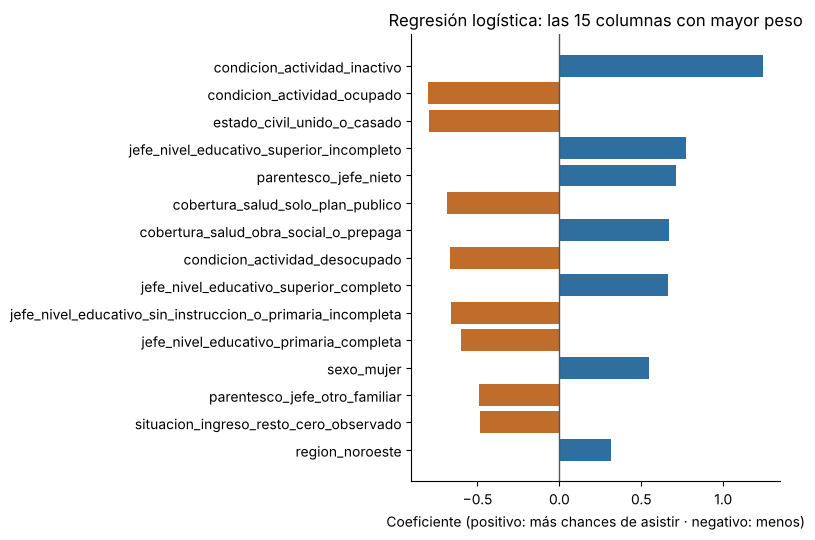

,coeficiente,factor sobre las chances (exp)
condicion_actividad_inactivo,1.24,3.47
condicion_actividad_ocupado,-0.80,0.45
estado_civil_unido_o_casado,-0.79,0.45
jefe_nivel_educativo_superior_incompleto,0.77,2.16
parentesco_jefe_nieto,0.71,2.04
cobertura_salud_solo_plan_publico,-0.68,0.50
cobertura_salud_obra_social_o_prepaga,0.67,1.95
condicion_actividad_desocupado,-0.67,0.51
jefe_nivel_educativo_superior_completo,0.66,1.94
jefe_nivel_educativo_sin_instruccion_o_primaria_incompleta,-0.66,0.52


In [21]:
# Coeficientes del modelo final, ordenados por magnitud
coeficientes = pd.DataFrame({"coeficiente": modelo_final.coef_[0]}, index=X_train_esc.columns)
coeficientes["factor sobre las chances (exp)"] = np.exp(coeficientes["coeficiente"])
coeficientes = coeficientes.reindex(coeficientes["coeficiente"].abs().sort_values(ascending=False).index)
coeficientes.to_csv(REPORTES + "coeficientes_regresion_logistica.csv")

principales = coeficientes.head(15).iloc[::-1]
fig, eje = plt.subplots(figsize=(8, 5.5))
eje.barh(principales.index, principales["coeficiente"],
         color=np.where(principales["coeficiente"] > 0, "#2f6f9f", "#c06c2b"))
eje.axvline(0, color="#555555", linewidth=1)
eje.set_xlabel("Coeficiente (positivo: más chances de asistir · negativo: menos)")
eje.set_title("Regresión logística: las 15 columnas con mayor peso")
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURAS + "modelo_coeficientes_logistica.png", dpi=110)
coeficientes.head(15).round(2)

**Lectura:**

- Las columnas con más peso son la **condición de actividad** (ser inactivo multiplica las chances de asistir por alrededor de 3,5; estar ocupado o desocupado las reduce), el **estado civil** (estar unido/a o casado/a las reduce a menos de la mitad), el **nivel educativo del jefe/a** (más chances con estudios superiores, menos con primaria o sin instrucción), la **cobertura de salud** (más con obra social o prepaga, menos con solo plan público), el **sexo** (las mujeres tienen más chances) y el **cero observado** en el ingreso del resto del hogar (menos chances). Esto es coherente con lo observado en el EDA.
- Entre las numéricas, la que más pesa es la cantidad de **menores de 10 años** en el hogar (cada desvío más reduce las chances alrededor de un 25 %). En cambio, la **edad** y el **percentil del ingreso** tienen coeficientes cercanos a 0, aunque en el EDA, mirados de a uno, se asociaban claramente con la asistencia. Una interpretación posible (hipótesis): esa información ya está contenida en otras variables relacionadas, como la condición de actividad y el estado civil para la edad, o la cobertura de salud y la educación del jefe/a para el ingreso. Por eso un coeficiente chico no significa que la variable no se relacione con la asistencia, sino que no agrega mucho **una vez consideradas las demás**.
- Que estas asociaciones coincidan con el EDA no prueba causalidad: indica que el modelo aprende las mismas relaciones que se ven en la muestra.

Las columnas one-hot de una misma variable se interpretan en conjunto (comparando sus coeficientes entre sí), porque la codificación no deja una categoría de referencia fija.

## 11. Cómo predicen los modelos (material para el video)

### 11.1 Regresión logística: un caso concreto y el umbral

Se toma un joven de la prueba y se muestra la probabilidad que estima el modelo y cómo el umbral define la clase.

In [22]:
# Un caso de la prueba: probabilidad estimada, clasificación con el umbral elegido y con 0,50
caso = int(np.argmin(np.abs(prob_prueba - 0.52)))        # un caso con probabilidad cercana a los umbrales
p = prob_prueba[caso]
print(f"Probabilidad estimada de asistir: {p:.2f}")
print(f"Con umbral 0,50 → {'asiste' if p >= 0.5 else 'no asiste'} · con umbral {UMBRAL:.2f} → "
      f"{'asiste' if p >= UMBRAL else 'no asiste'}")
print(f"Valor real: {'asiste' if y_test.iloc[caso] == 1 else 'no asiste'}")

Probabilidad estimada de asistir: 0.52
Con umbral 0,50 → asiste · con umbral 0.55 → no asiste
Valor real: no asiste


Este caso muestra para qué sirve el umbral: con una probabilidad de asistir apenas por encima de 0,50, el corte habitual lo clasificaría como "asiste", mientras que el umbral elegido por validación lo marca como "no asiste" y, por lo tanto, como destinatario del acompañamiento. Del mismo modo, una probabilidad de 0,35 quedaría como "no asiste" con cualquiera de los dos umbrales.

### 11.2 KNN: por qué importa escalar

KNN mide distancias entre jóvenes. Sin escalar, el percentil del ingreso (de 0 a 100) pesaría mucho más en la distancia que, por ejemplo, la cantidad de menores (de 0 a 7) o las columnas one-hot (0 o 1). Se compara en validación el mejor KNN con la matriz escalada y la misma configuración con la matriz sin escalar:

In [23]:
# Mismo KNN, con y sin escalado (validación cruzada)
for nombre, X in [("con escalado", X_train_esc), ("sin escalado", X_train_sin)]:
    r = cross_validate(knn.best_estimator_, X, y_train, groups=grupos, cv=validacion, scoring=METRICAS, n_jobs=-1)
    print(f"KNN {nombre}: F1 no asiste = {r['test_f1_no_asiste'].mean():.3f} · "
          f"recall no asiste = {r['test_recall_no_asiste'].mean():.3f}")

KNN con escalado: F1 no asiste = 0.699 · recall no asiste = 0.648
KNN sin escalado: F1 no asiste = 0.622 · recall no asiste = 0.556


Sin escalado, KNN empeora: las distancias quedan dominadas por las variables con valores más grandes. El efecto de K se ve en el gráfico de la sección 5.2.

### 11.3 Árbol de decisión: el recorrido de un caso

El mejor árbol en validación es poco profundo, así que se puede mostrar completo. Cada caja indica la pregunta, la cantidad de jóvenes (`samples`), cuántos hay de cada clase (`value`: no asiste, asiste) y la clase mayoritaria.

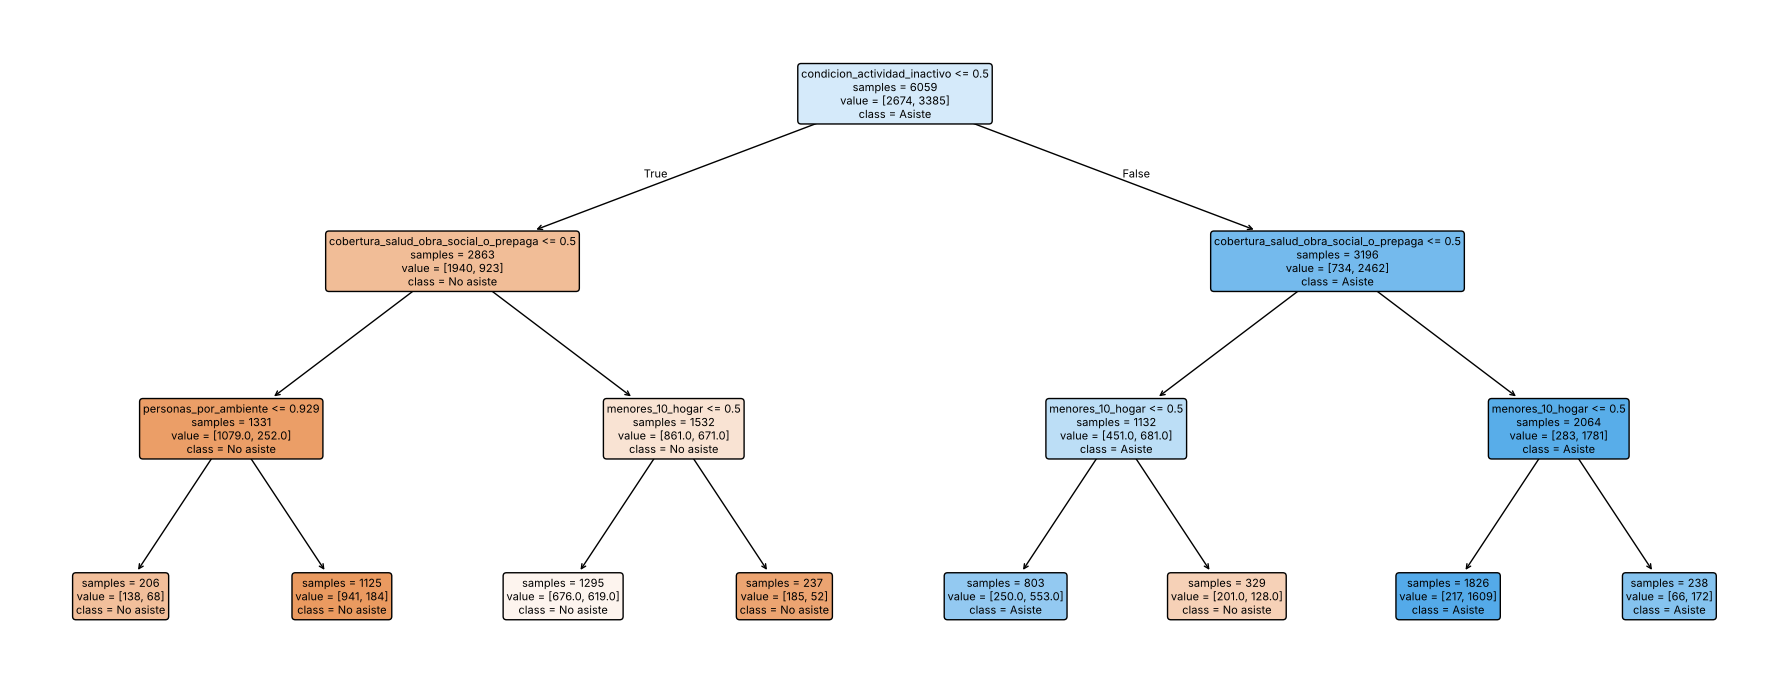

In [24]:
# Árbol final (mejor configuración en validación) entrenado con todo el entrenamiento
arbol_final = arbol.best_estimator_
fig, eje = plt.subplots(figsize=(18, 7))
plot_tree(arbol_final, feature_names=list(X_train_sin.columns), class_names=["No asiste", "Asiste"],
          filled=True, rounded=True, impurity=False, fontsize=8, ax=eje)
plt.tight_layout()
plt.savefig(FIGURAS + "modelo_arbol_decision.png", dpi=110)

In [25]:
# Recorrido de un joven de la prueba por el árbol: cada pregunta y la respuesta para ese caso
caso_arbol = X_test_sin.iloc[[0]]
nodos = arbol_final.decision_path(caso_arbol).indices
estructura = arbol_final.tree_
for nodo in nodos:
    if estructura.children_left[nodo] == -1:          # nodo hoja: clasificación final
        clase = "asiste" if estructura.value[nodo][0].argmax() == 1 else "no asiste"
        print(f"→ Hoja: el árbol clasifica como '{clase}'")
    else:
        variable = X_train_sin.columns[estructura.feature[nodo]]
        valor = caso_arbol.iloc[0][variable]
        corte = estructura.threshold[nodo]
        print(f"¿{variable} <= {corte:.2f}?  El caso tiene {valor:.2f} → {'sí' if valor <= corte else 'no'}")
print("Valor real:", "asiste" if y_test.iloc[0] == 1 else "no asiste")

¿condicion_actividad_inactivo <= 0.50?  El caso tiene 1.00 → no
¿cobertura_salud_obra_social_o_prepaga <= 0.50?  El caso tiene 1.00 → no
¿menores_10_hogar <= 0.50?  El caso tiene 0.00 → sí
→ Hoja: el árbol clasifica como 'asiste'
Valor real: asiste


En las columnas one-hot (0 o 1), una pregunta del tipo `condicion_actividad_inactivo <= 0,5` significa "¿el joven **no** es inactivo?".

In [26]:
# Guardado del modelo final y su umbral, para poder reutilizarlo sin reentrenar
joblib.dump({"modelo": modelo_final, "umbral": UMBRAL, "columnas": list(X_train_esc.columns)},
            MODELOS + "regresion_logistica_final.joblib")
print("Modelo guardado en models/regresion_logistica_final.joblib")

Modelo guardado en models/regresion_logistica_final.joblib


## 12. Conclusiones y limitaciones

**Conclusiones (sobre la muestra analizada)**

- Con información disponible en el momento de la encuesta, los modelos identifican a alrededor de 7 u 8 de cada 10 jóvenes que no asisten al nivel superior, frente a ninguno de la línea base.
- Regresión logística, SVM y Random Forest obtienen resultados equivalentes en validación; se eligió la **regresión logística** por ser la más simple e interpretable y porque permite ajustar el umbral al objetivo.
- El desempeño en la prueba (2026) es parecido al de validación (2025), lo que sugiere que el modelo puede aplicarse a un trimestre nuevo de la EPH; para confirmarlo haría falta evaluarlo con más trimestres.
- En el modelo final, las variables con más peso son la condición de actividad, el estado civil, el nivel educativo del jefe/a, la cobertura de salud, el sexo, los menores de 10 años en el hogar y la situación del ingreso del resto del hogar. La edad y el percentil del ingreso aportan poco una vez consideradas las demás.

**Limitaciones**

- **Zona gris:** buena parte del desempeño depende de la condición de actividad, que puede ser en parte consecuencia de estudiar. Sin esa variable el modelo sigue siendo útil, pero menos preciso.
- **Asociación no es causalidad:** los coeficientes no indican qué pasaría si cambiara una característica del joven.
- **Alcance:** los datos se usan sin ponderar; los resultados describen la muestra de la EPH en aglomerados urbanos, no a toda la población joven.
- **Momento de la medición:** se predice la asistencia actual, no si el joven empezará o abandonará estudios en el futuro.
- **Ingresos:** casi 3 de cada 10 hogares no respondieron ingresos; la imputación no recupera ese dato.

**Trabajo futuro**

- Reentrenar y evaluar con cada nueva EPH trimestral (el "segundo tiempo" del planteo), para ver si el desempeño se mantiene.
- Incorporar variables que hoy no están disponibles, como la oferta de instituciones de nivel superior cercanas al aglomerado.
- Estudiar con más detalle la relación entre trabajo y estudio, por ejemplo, con modelos separados para jóvenes ocupados e inactivos.